In [1]:
from google.colab import drive
import os
import torch
from torchvision import transforms, datasets
from torch.utils.data import Subset, DataLoader
import matplotlib.pyplot as plt
import pandas as pd
from collections import Counter
import math
from PIL import Image

drive.mount('/content/drive')
ROOT = "/content/drive/MyDrive/dane_psy_koty"

eval_tf = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3),
])

train_tf = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3),
])

Mounted at /content/drive


In [2]:
g = torch.Generator().manual_seed(42)
n = len(datasets.ImageFolder(ROOT))
perm = torch.randperm(n, generator=g).tolist()

n_val = int(0.2 * n)
val_idx, train_idx = perm[:n_val], perm[n_val:]

train_ds = Subset(datasets.ImageFolder(ROOT, transform=train_tf), train_idx)
val_ds = Subset(datasets.ImageFolder(ROOT, transform=eval_tf), val_idx)

train_dl = DataLoader(train_ds, batch_size=16, shuffle=True)
val_dl = DataLoader(val_ds, batch_size=16, shuffle=False)

In [3]:
train_targets = [train_ds.dataset.targets[i] for i in train_ds.indices]
val_targets = [val_ds.dataset.targets[i] for i in val_ds.indices]

train_counts = Counter(train_targets)
val_counts = Counter(val_targets)

stats = {
    "Część zbioru": ["Treningowy", "Walidacyjny"],
    "Liczba klas": [len(train_ds.dataset.classes), len(val_ds.dataset.classes)],
    f"{train_ds.dataset.classes[0]}": [train_counts[0], val_counts[0]],
    f"{train_ds.dataset.classes[1]}": [train_counts[1], val_counts[1]],
    "Rozmiar tensora": [str(train_ds.dataset[0][0].shape), str(val_ds.dataset[0][0].shape)]
}

df_stats = pd.DataFrame(stats)
print(f"Mapowanie klas (class_to_idx): {train_ds.dataset.class_to_idx}\n")
display(df_stats)

Mapowanie klas (class_to_idx): {'koty': 0, 'psy': 1}



,Część zbioru,Liczba klas,koty,psy,Rozmiar tensora
0,Treningowy,2,26,22,"torch.Size([3, 128, 128])"
1,Walidacyjny,2,4,8,"torch.Size([3, 128, 128])"


Kształt paczki: torch.Size([16, 3, 128, 128])
Typ tensora: torch.float32
Zakres wartości tensora: min = -1.000, max = 1.000
Etykiety w paczce (tensor): [0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1]



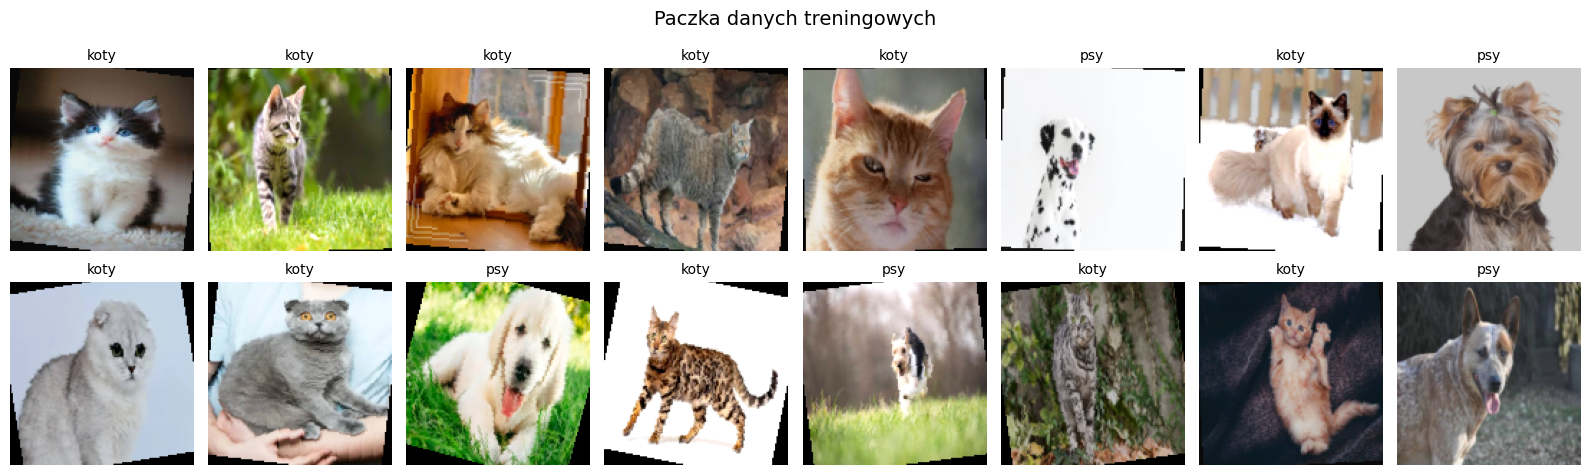

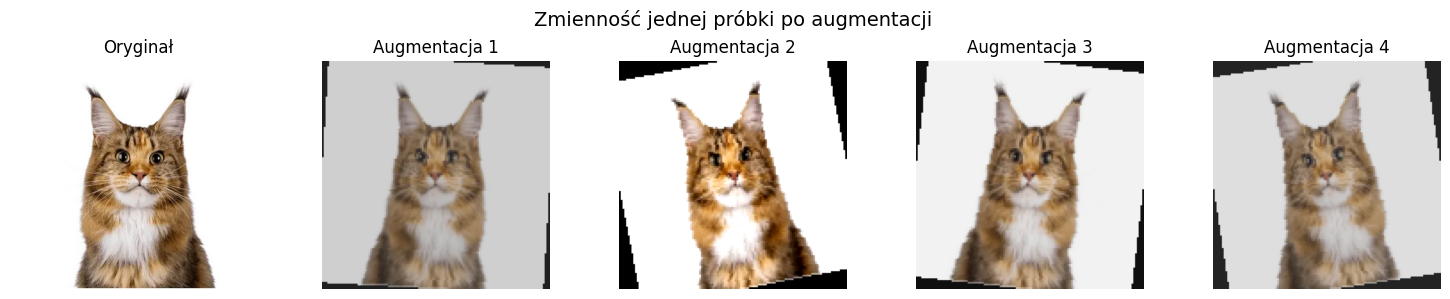

In [4]:
xb, yb = next(iter(train_dl))

print(f"Kształt paczki: {xb.shape}")
print(f"Typ tensora: {xb.dtype}")
print(f"Zakres wartości tensora: min = {xb.min().item():.3f}, max = {xb.max().item():.3f}")
print(f"Etykiety w paczce (tensor): {yb.tolist()}\n")

n_images = len(xb)
cols = 8
rows = math.ceil(n_images / cols)

fig, axes = plt.subplots(rows, cols, figsize=(16, 2.5 * rows))
for i, ax in enumerate(axes.flat):
    if i < n_images:
        img_denorm = xb[i] * 0.5 + 0.5
        ax.imshow(img_denorm.permute(1, 2, 0).numpy())
        ax.set_title(train_ds.dataset.classes[yb[i]], fontsize=10)
    ax.axis("off")
plt.suptitle("Paczka danych treningowych", fontsize=14)
plt.tight_layout()
plt.show()

sample_idx = train_ds.indices[0]
sample_img_path = train_ds.dataset.imgs[sample_idx][0]
img_pil = Image.open(sample_img_path)

aug_tf = transforms.Compose(train_tf.transforms[:-2])

fig, axes = plt.subplots(1, 5, figsize=(15, 3))
axes[0].imshow(img_pil)
axes[0].set_title("Oryginał")
axes[0].axis("off")

for i in range(1, 5):
    img_aug = aug_tf(img_pil)
    axes[i].imshow(img_aug)
    axes[i].set_title(f"Augmentacja {i}")
    axes[i].axis("off")
plt.suptitle("Zmienność jednej próbki po augmentacji", fontsize=14)
plt.tight_layout()
plt.show()